# EDA idea 1: pea protein datasets

**Idea 1 in one line:** estimate the probability that protein pea grown in a region of France, of a given type (winter or spring) and under the weather of a given season, reaches a target protein content (for example ≥ 23% dry matter), and its relative yield.

This notebook is **didactic**: the goal is for you to quickly understand which columns each dataset has, what units they are in and how they join. There are no models: only loading, description, counts, simple plots and joins (hackathon rule: no training, no split, no cross-validation).

| Section | Dataset | Role |
|---|---|---|
| 1 | Pea_dataset (INRAE) | Trials: labels (protein, yield) and inputs (soil, variety, management) |
| 2 | SAFRAN / SIM2 (Météo-France) | Daily climate on an 8 km grid |
| 3 | Agreste SAA long series | On-farm area and yield by department |
| 4 | RPG | Where pea is grown (winter vs spring) |
| 5 | Terres Univia quality surveys | Protein arriving at the silos |
| 6 | How they join | The keys, with an end-to-end example |
| 7 | Summary | Table of all datasets |

Details of the audit are in `research/idea1_pea_protein_data.md`, `research/datasets/safran.md` and `research/eda_idea1/README.md`.

## 0. Setup

Everything is downloaded to `DATA_DIR` (default `../data/raw`, relative to this notebook). You can change it with the `HTF_DATA_DIR` environment variable.

The `fetch` function downloads a file **only if it does not exist**, so you can run the notebook several times without re-downloading. The heavy one is SAFRAN (~137 MB per year); the rest weighs a few MB.

> **Heads-up:** `data/` is never committed (it is in `.gitignore`). The data is downloaded from the official sources.

In [1]:
import os
import time
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.figsize"] = (9, 4)

DATA_DIR = Path(os.environ.get("HTF_DATA_DIR", "../data/raw"))
DATA_DIR.mkdir(parents=True, exist_ok=True)
T0 = time.time()


def fetch(url, dest):
    # Download url to dest only if dest is missing (writes to .part first)
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    tmp = dest.with_name(dest.name + ".part")
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    tmp.rename(dest)
    print(f"downloaded {dest.name}: {dest.stat().st_size / 1e6:.1f} MB")
    return dest


print("DATA_DIR =", DATA_DIR.resolve())

DATA_DIR = /private/tmp/claude-501/-Users-fede-bello-develop-hack-the-fork/9fe23a79-8d36-4ec5-81a7-19ddb7a4cabc/scratchpad/en_nb/data


## 1. Pea_dataset (main dataset)

**What it is:** a network of pea trials in France (2002-2024, useful 2013-2024) where several varieties are sown at each site and year, and grain yield, grain protein, flowering dates, etc. are measured. It combines variety trials from Terres Inovia / GEVES (the vast majority) with research trials (Burstin et al. 2021, Vocanson & Jeuffroy 2008, Gaudio et al. 2024).

- **Who:** A. Diallo, V. Biarnès, M. Prudent, M. Chanis, M.-H. Jeuffroy, S. Gervois, A. Van Boxsom, W. Horrigue, A. Larmure (INRAE Agroécologie Dijon, Terres Inovia, INRAE Agronomie Palaiseau).
- **Where:** Recherche Data Gouv, doi [10.57745/FW78RE](https://doi.org/10.57745/FW78RE), version 1 (August 2026).
- **License:** Etalab 2.0 (free use, citing the source).

It has 4 files:

| File | What it contains |
|---|---|
| `metadata` | Variable dictionary: file, variable, description, unit |
| `trials_data` | One row per **situation** (site × variety × year [× management mode]): location, soil, variety, management |
| `crop_traits_data` | The **measurements**, in long format: one row per situation × variable |
| `weather_data.zip` | 158 daily weather CSVs, one per site |

In [2]:
PEA = DATA_DIR / "pea"
BASE = "https://entrepot.recherche.data.gouv.fr/api/access/datafile"
pea_files = {
    "trials_data.csv": f"{BASE}/764684?format=original",
    "crop_traits_data.csv": f"{BASE}/764685?format=original",
    "metadata.csv": f"{BASE}/764683?format=original",
    "weather_data.zip": f"{BASE}/764686",
}
for name, url in pea_files.items():
    fetch(url, PEA / name)
sorted(p.name for p in PEA.iterdir())

['crop_traits_data.csv', 'metadata.csv', 'trials_data.csv', 'weather_data.zip']

### 1.1 `metadata`: the dictionary

We start here because it explains each column of the other files, with its unit. The CSVs come with a BOM, which is why `encoding="utf-8-sig"` is used.

In [3]:
meta = pd.read_csv(PEA / "metadata.csv", encoding="utf-8-sig")
with pd.option_context("display.max_rows", 100, "display.max_colwidth", 90):
    display(meta)

,file_or_archive,variable_names,descriptions,units
0,trials_data,situation_id,Unique identifier of the agro-pedoclimatic situation composed as following site_name__...,-
1,trials_data,data_source,Origin of the dataset (institution or author),-
2,trials_data,site_name,Name of the experimental site,-
3,trials_data,postal_code,Postal code of the site,-
4,trials_data,longitude,Longitude of the site,°
5,trials_data,latitude,Latitude of the site,°
6,trials_data,harvest_year,Harvest year of the crop,-
7,trials_data,weather_file,Name of the associated weather file,-
8,trials_data,soil_class_usda,Soil texture class according to USDA classification,-
9,trials_data,soil_depth,Class of the soil depth,cm


### 1.2 `trials_data`: one row per situation

A **situation** is a variety sown at a site in a given year. `situation_id` is `SITE__Genotype_N__YEAR`, with a `__Mk` suffix when the same site-year has several management modes (research trials).

In [4]:
trials = pd.read_csv(PEA / "trials_data.csv", encoding="utf-8-sig")
print(trials.shape)
trials["postal_code"] = trials["postal_code"].astype(str).str.zfill(5)
trials["dep"] = trials["postal_code"].str[:2]  # department code, added by us
trials.head(3)

(4450, 33)


,situation_id,data_source,site_name,postal_code,longitude,latitude,harvest_year,weather_file,soil_class_usda,soil_depth,soil_clay_content,soil_silt_content,soil_sand_content,soil_awc,soil_CN_ratio,soil_caco3_content,soil_N_content,previous_crop,pea_type,genotype,Hr_allele,seed_color,seed_prot,flow_precocity,lodg_tolerance,cold_tolerance,TSW,sowing_date,sowing_density,irrigation_event_1,irrigation_event_2,irrigation_event_3,management,dep
0,BRETENIERE__Genotype_74__2015__M1,Burstin et al. (2021),BRETENIERE,21110,5.103,47.236,2015,BRETENIERE_weather.csv,Silty Clay,100,44.1,49.7,6.2,99.83,9.74,68.23,1.43,NaN,WINTER,Genotype_74,NO,yellow,NaN,NaN,NaN,highly tolerant,<180,2014-10-20,75,0,0,0,S1-Nirg-J,21
1,BRETENIERE__Genotype_11__2015__M1,Burstin et al. (2021),BRETENIERE,21110,5.103,47.236,2015,BRETENIERE_weather.csv,Silty Clay,100,44.1,49.7,6.2,99.83,9.74,68.23,1.43,NaN,WINTER,Genotype_11,YES,green,NaN,NaN,NaN,highly tolerant,<180,2014-10-20,50,0,0,0,S1-Nirg-G,21
2,BRETENIERE__Genotype_74__2015__M2,Burstin et al. (2021),BRETENIERE,21110,5.103,47.236,2015,BRETENIERE_weather.csv,Silty Clay,100,44.1,49.7,6.2,99.83,9.74,68.23,1.43,NaN,WINTER,Genotype_74,NO,yellow,NaN,NaN,NaN,highly tolerant,<180,2014-10-23,90,0,0,0,S2-Nirg-J,21


In [5]:
trials.dtypes.value_counts()

str        22
float64     9
int64       3
Name: count, dtype: int64

The 33 columns are grouped as follows:

| Group | Columns | In words |
|---|---|---|
| Identification | `situation_id`, `data_source`, `genotype`, `harvest_year` | Who ran the trial, which variety (anonymized), harvest year |
| Location | `site_name`, `postal_code`, `longitude`, `latitude`, `weather_file` | Where the site is and which weather file goes with it. The department is the first 2 digits of the postal code (we add it as `dep`) |
| Soil | `soil_class_usda`, `soil_depth`, `soil_clay/silt/sand_content`, `soil_awc`, `soil_CN_ratio`, `soil_caco3_content`, `soil_N_content` | Texture (%), depth (cm, in classes), available water (mm), C/N, limestone and N (g/kg). Constant per site |
| Variety | `pea_type`, `Hr_allele`, `seed_color`, `seed_prot`, `flow_precocity`, `lodg_tolerance`, `cold_tolerance`, `TSW` | Traits **declared** by the breeder (catalogue), not measured in the trial. `seed_prot` is a **class** of protein, not a number |
| Management | `previous_crop`, `sowing_date`, `sowing_density`, `irrigation_event_1..3`, `management` | Previous crop, sowing date and density (plants/m²), irrigation as text `date=...$dose=mm`, management mode codes |

**Missing values per column** (in %). The large ones are `management` (research trials only), `cold_tolerance` and `Hr_allele` (only reported for winter) and `previous_crop`.

In [6]:
na = trials.isna().mean().mul(100).round(1).sort_values(ascending=False)
na[na > 0].to_frame("% faltante")

,% faltante
management,87.7
cold_tolerance,60.9
Hr_allele,60.8
previous_crop,41.1
lodg_tolerance,16.7
flow_precocity,15.4
seed_prot,14.0
seed_color,1.9
TSW,1.3


**Key categorical variables:** pea type, breeder protein class and soil class.

In [7]:
for col in ["pea_type", "seed_prot", "soil_class_usda", "data_source"]:
    display(trials[col].value_counts(dropna=False).to_frame(col))

,pea_type
pea_type,
SPRING,2705
WINTER,1745


,seed_prot
seed_prot,
medium,1665
high,979
NaN,625
low,546
very high,530
medium/high,105


,soil_class_usda
soil_class_usda,
Silty Clay Loam,1018
Loam,984
Silt Loam,971
Clay Loam,678
Silty Clay,391
Sandy Loam,285
Clay,76
Sandy Clay Loam,47


,data_source
data_source,
Terres Inovia GEVES and partners,3936
Burstin et al. (2021),425
Vocanson and Jeuffroy (2008),54
Gaudio et al. (2024),35


**Network size:** how many sites, years, varieties and departments there are.

In [8]:
pd.Series({
    "situations": len(trials),
    "sites": trials["site_name"].nunique(),
    "years": trials["harvest_year"].nunique(),
    "genotypes": trials["genotype"].nunique(),
    "departments": trials["dep"].nunique(),
    "weather files": trials["weather_file"].nunique(),
}).to_frame("n")

,n
situations,4450
sites,158
years,22
genotypes,117
departments,40
weather files,158


Situations per year and type. 2016 has no winter trials, and since 2019 spring dominates.

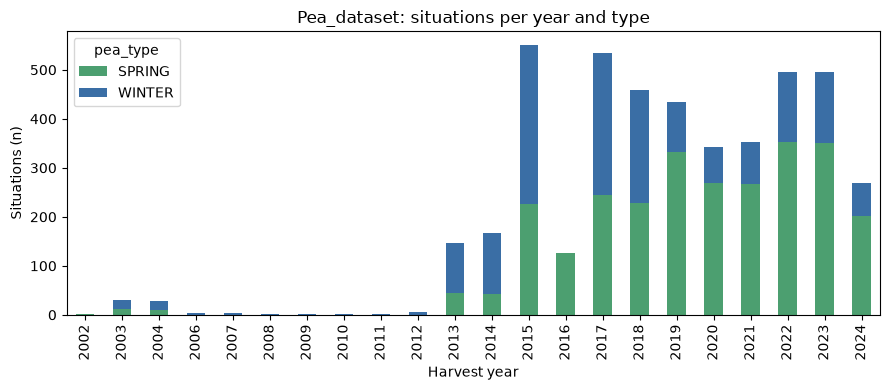

In [9]:
by_year = trials.groupby(["harvest_year", "pea_type"]).size().unstack(fill_value=0)
ax = by_year.plot.bar(stacked=True, color={"SPRING": "#4C9F70", "WINTER": "#3A6EA5"})
ax.set_xlabel("Harvest year")
ax.set_ylabel("Situations (n)")
ax.set_title("Pea_dataset: situations per year and type")
plt.tight_layout()

### 1.3 `crop_traits_data`: the measurements, in long format

**Long vs wide:** in *wide* format each variable would be a column (one row per situation). Here it is in *long* format: each row is **one measurement** (`situation_id`, `variable`, `value`). This is convenient because not every situation measures the same things (almost nobody measures LAI, everybody measures flowering). For analysis, we pivot it to wide.

Heads-up: `value` comes as text, because it mixes dates and numbers.

In [10]:
traits = pd.read_csv(PEA / "crop_traits_data.csv", encoding="utf-8-sig")
print(traits.shape)
traits.head(3)

(27168, 11)


,situation_id,data_source,site_name,harvest_year,pea_type,genotype,sowing_date,harvest_date,measurement_date,variable,value
0,ACHIET_LE_GRAND__Genotype_27__2018,Terres Inovia GEVES and partners,ACHIET_LE_GRAND,2018,SPRING,Genotype_27,2018-03-26,2018-07-27,2018-05-30,start_flo_date,2018-05-30
1,ACHIET_LE_GRAND__Genotype_27__2018,Terres Inovia GEVES and partners,ACHIET_LE_GRAND,2018,SPRING,Genotype_27,2018-03-26,2018-07-27,2018-07-27,seed_weight,0.248
2,ACHIET_LE_GRAND__Genotype_27__2018,Terres Inovia GEVES and partners,ACHIET_LE_GRAND,2018,SPRING,Genotype_27,2018-03-26,2018-07-27,2018-07-27,tsw_14,283.11


In [11]:
traits["variable"].value_counts().to_frame("rows")

,rows
variable,
start_flo_date,4450
yield_14,4230
tsw_14,3369
protein_content,3326
plant_height,2762
end_flo_date,2640
seed_weight,2519
dry_biomass,998
plant_density,689


We pivot the three variables that matter most for idea 1. Yield and protein have only one row per situation, so the pivot loses nothing.

| Variable | Unit | Comment |
|---|---|---|
| `protein_content` | % (almost certainly % of dry matter, N × 6.25) | The dictionary only says "%"; it matches the national series in % DM |
| `yield_14` | q/ha (quintals per hectare) at 14% moisture | 1 q/ha = 100 kg/ha |
| `start_flo_date` | date | Start of flowering, measured in all situations |

In [12]:
keep = ["protein_content", "yield_14", "start_flo_date"]
wide = (traits[traits["variable"].isin(keep)]
        .pivot_table(index="situation_id", columns="variable", values="value", aggfunc="first"))
wide["protein_content"] = pd.to_numeric(wide["protein_content"])
wide["yield_14"] = pd.to_numeric(wide["yield_14"])
wide["start_flo_date"] = pd.to_datetime(wide["start_flo_date"])
print(wide.shape)
wide.describe()

(4450, 3)


variable,protein_content,start_flo_date,yield_14
count,3326.000000,4450,4230.000000
mean,22.883163,2019-02-18 20:25:46.786516,49.534184
min,16.100000,2002-05-27 00:00:00,14.000000
25%,21.500000,2017-04-15 00:00:00,39.025000
50%,23.000000,2019-05-18 00:00:00,49.100000
75%,24.400000,2022-05-01 00:00:00,60.100000
max,31.400000,2024-07-02 00:00:00,100.200000
std,2.238745,NaN,14.633002


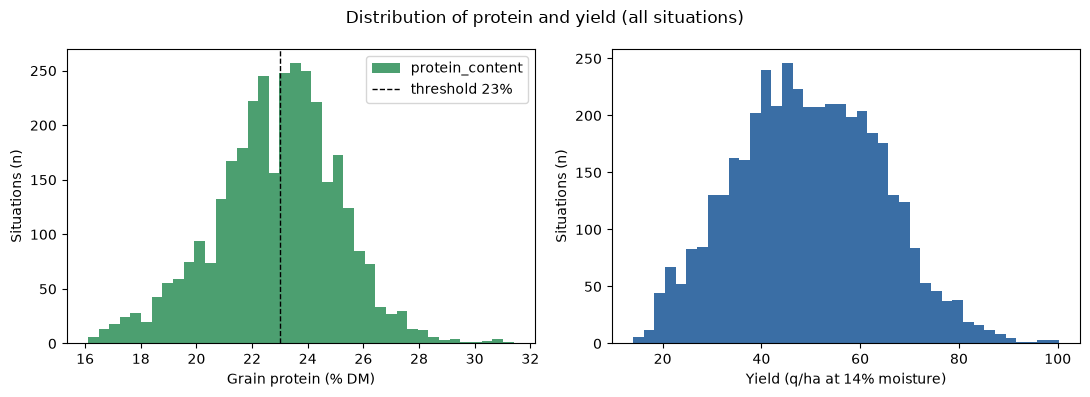

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
wide["protein_content"].plot.hist(bins=40, ax=axes[0], color="#4C9F70")
axes[0].axvline(23, color="k", ls="--", lw=1, label="threshold 23%")
axes[0].set_xlabel("Grain protein (% DM)")
axes[0].set_ylabel("Situations (n)")
axes[0].legend()
wide["yield_14"].plot.hist(bins=40, ax=axes[1], color="#3A6EA5")
axes[1].set_xlabel("Yield (q/ha at 14% moisture)")
axes[1].set_ylabel("Situations (n)")
fig.suptitle("Distribution of protein and yield (all situations)")
plt.tight_layout()

### 1.4 The "trial": site × year × type

A row is a variety, but all varieties of the same site-year share soil, weather and management. So we define the **trial** = site × harvest year × type (winter or spring). This is the unit that the environment model has to explain.

We join `trials` with the wide measurements by `situation_id`.

In [14]:
df = trials.merge(wide, left_on="situation_id", right_index=True, how="left")
df["trial"] = df["site_name"] + "|" + df["harvest_year"].astype(str) + "|" + df["pea_type"]
prot = df.dropna(subset=["protein_content"])
pd.Series({
    "trials (all)": df["trial"].nunique(),
    "trials with protein": prot["trial"].nunique(),
    "site-years with protein": prot.groupby(["site_name", "harvest_year"]).ngroups,
    "situations with protein": len(prot),
}).to_frame("n")

,n
trials (all),355
trials with protein,256
site-years with protein,224
situations with protein,3326


Trial-level table: mean protein, spread between varieties and number of varieties.

In [15]:
trial_agg = (prot.groupby(["site_name", "harvest_year", "pea_type", "dep"])
       .agg(n_var=("protein_content", "size"),
            prot_mean=("protein_content", "mean"),
            prot_sd=("protein_content", "std"),
            yield_mean=("yield_14", "mean"))
       .round(2).reset_index())
trial_agg.sort_values(["harvest_year", "site_name"]).head(10)

,site_name,harvest_year,pea_type,dep,n_var,prot_mean,prot_sd,yield_mean
100,ESTREES_MONS,2003,SPRING,80,2,21.25,0.49,68.20
101,ESTREES_MONS,2003,WINTER,80,8,19.27,0.84,70.06
120,GRIGNON,2003,SPRING,73,4,23.25,1.97,59.70
121,GRIGNON,2003,WINTER,73,6,21.18,0.96,66.15
102,ESTREES_MONS,2004,SPRING,80,3,23.23,0.58,69.57
103,ESTREES_MONS,2004,WINTER,80,9,21.23,0.99,65.09
122,GRIGNON,2004,SPRING,73,5,21.24,2.30,46.48
123,GRIGNON,2004,WINTER,73,8,19.78,1.73,53.39
54,BRETENIERE,2013,SPRING,21,6,21.97,0.61,54.97
55,BRETENIERE,2013,WINTER,21,16,22.54,0.53,48.88


**Why the trial is the unit:** we compare how much protein varies **between trials** (spread of the trial means) against how much it varies **within a trial** (typical spread between varieties of the same site-year-type). If the first is much larger, the environment dominates and the real information lives in ~250 trials, not in ~3,300 rows.

In [16]:
trial_agg5 = trial_agg[trial_agg["n_var"] >= 5]
pd.Series({
    "SD between trials (of the means)": trial_agg5["prot_mean"].std(),
    "median SD within a trial": trial_agg5["prot_sd"].median(),
}).round(2).to_frame("protein, % points")

,"protein, % points"
SD between trials (of the means),2.02
median SD within a trial,0.82


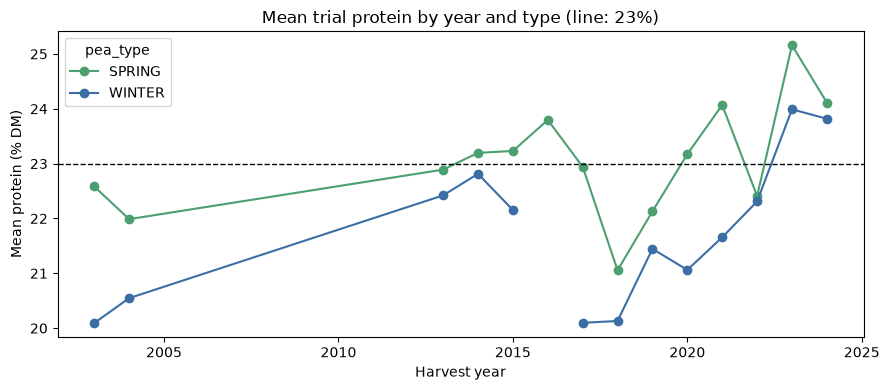

In [17]:
yr = prot.groupby(["harvest_year", "pea_type"])["protein_content"].mean().unstack()
ax = yr.plot(marker="o", color={"SPRING": "#4C9F70", "WINTER": "#3A6EA5"})
ax.axhline(23, color="k", ls="--", lw=1)
ax.set_xlabel("Harvest year")
ax.set_ylabel("Mean protein (% DM)")
ax.set_title("Mean trial protein by year and type (line: 23%)")
plt.tight_layout()

### 1.5 The weather inside the zip

158 daily CSVs, one per site (`trials.weather_file` says which). Separator `;`.

| Column | What it is | Unit |
|---|---|---|
| `AN`, `MOIS`, `JOUR` | Year, month, day | |
| `ETPP` | Potential evapotranspiration (Penman) | mm/day |
| `TMC` | Mean temperature | °C |
| `RG` | Global radiation | **J/cm²/day** (divide by 100 for MJ/m²) |
| `RR` | Rain | mm/day |
| `TX`, `TN` | Maximum and minimum temperature | °C |

Heads-up: each file covers **only the years with a trial** at that site (typically 2 years: sowing and harvest; repeated sites such as CONDOM have more), so it is no good for climatology. For that, see SAFRAN (section 2).

In [18]:
wz = zipfile.ZipFile(PEA / "weather_data.zip")
members = {Path(n).name.lower(): n for n in wz.namelist() if n.endswith(".csv")}
print(len(members), "files; examples:", list(members)[:5])
missing = set(trials["weather_file"].str.lower()) - set(members)
print("weather_file with no file in the zip:", missing or "none")


def read_weather(weather_file):
    # Read one site's daily weather from the zip (file names are case-mixed)
    w = pd.read_csv(wz.open(members[weather_file.lower()]), sep=";")
    w["date"] = pd.to_datetime(dict(year=w["AN"], month=w["MOIS"], day=w["JOUR"]))
    return w

158 files; examples: ['achiet_le_grand_weather.csv', 'ageville_weather.csv', 'aigrefeuille_d_aunis_weather.csv', 'airaines_weather.csv', 'amanvillers_weather.csv']
weather_file with no file in the zip: none


In [19]:
w = read_weather("condom_weather.csv")
print("CONDOM:", w["date"].min().date(), "to", w["date"].max().date(), "|", len(w), "days")
w.head()

CONDOM: 2014-01-01 to 2024-12-31 | 4018 days


,AN,MOIS,JOUR,ETPP,TMC,RG,RR,TX,TN,date
0,2014,1,1,0.65,8.20,446.59285,3.0,11.0,5.4,2014-01-01
1,2014,1,2,0.89,11.15,478.40265,2.4,13.9,8.4,2014-01-02
2,2014,1,3,0.34,11.40,143.56265,6.3,13.9,8.9,2014-01-03
3,2014,1,4,1.16,10.15,277.49865,9.5,13.5,6.8,2014-01-04
4,2014,1,5,0.61,7.80,334.00290,1.2,10.4,5.2,2014-01-05


A spring season at CONDOM (Gers), from 1 Sep 2017 to 31 Aug 2018: daily temperatures and rainfall.

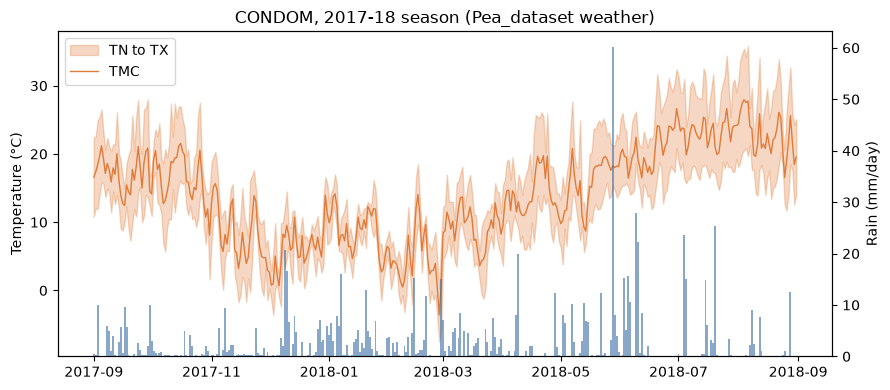

In [20]:
season = w[(w["date"] >= "2017-09-01") & (w["date"] <= "2018-08-31")]
fig, ax = plt.subplots()
ax.fill_between(season["date"], season["TN"], season["TX"], color="#E07B39", alpha=0.3, label="TN to TX")
ax.plot(season["date"], season["TMC"], color="#E07B39", lw=1, label="TMC")
ax.set_ylabel("Temperature (°C)")
ax2 = ax.twinx()
ax2.bar(season["date"], season["RR"], color="#3A6EA5", width=1, alpha=0.6)
ax2.set_ylabel("Rain (mm/day)")
ax.set_title("CONDOM, 2017-18 season (Pea_dataset weather)")
ax.legend(loc="upper left")
plt.tight_layout()

### 1.6 Known gotchas

1. **Wrong coordinates** at 5 sites (the point falls in a different department than the postal code): AVANCON, DIOU, GRIGNON, GRIGNON_INRAE, ANGERS_JAILLIERE. For GRIGNON it is the postal code that is wrong (73 instead of 78).
2. **Impossible harvest date:** `LE_RHEU__Genotype_58__2013__M1` has its harvest in 2017 for a 2013 sowing.
3. **`seed_prot` is a class** from the catalogue (low ... very high), not the measured protein.
4. **Anonymized genotypes** (`Genotype_N`): varieties cannot be recommended by name.
5. **Protein is missing for whole site-years**, especially in 2015, 2017 and 2018, not at random within the trial.

In [21]:
bad = ["AVANCON", "DIOU", "GRIGNON", "GRIGNON_INRAE", "ANGERS_JAILLIERE"]
trials[trials["site_name"].isin(bad)].drop_duplicates("site_name")[
    ["site_name", "postal_code", "latitude", "longitude"]]

,site_name,postal_code,latitude,longitude
5,GRIGNON,73200,48.838,1.953
483,ANGERS_JAILLIERE,49000,47.450,-0.962
512,GRIGNON_INRAE,73200,48.150,1.150
3691,DIOU,36260,46.523,3.743
3904,AVANCON,08300,44.536,6.191


In [22]:
traits.loc[(traits["situation_id"] == "LE_RHEU__Genotype_58__2013__M1")
           & (traits["variable"] == "yield_14"),
           ["situation_id", "sowing_date", "harvest_date"]]

,situation_id,sowing_date,harvest_date
15546,LE_RHEU__Genotype_58__2013__M1,2013-03-06,2017-07-16


In [23]:
sy = df.groupby(["harvest_year", "site_name"])["protein_content"].apply(lambda s: s.notna().mean())
miss = pd.DataFrame({
    "site-years": sy.groupby(level=0).size(),
    "no protein at all": (sy == 0).groupby(level=0).sum(),
    "partial": ((sy > 0) & (sy < 1)).groupby(level=0).sum(),
})
miss.loc[2013:]

,site-years,no protein at all,partial
harvest_year,,,
2013,11,5,3
2014,8,2,1
2015,37,19,7
2016,10,1,0
2017,36,20,3
2018,29,10,2
2019,30,1,0
2020,28,1,3
2021,21,2,2


## 2. SAFRAN / SIM2 (daily climate on a grid)

**What it is:** a Météo-France reanalysis (SAFRAN for the atmosphere, ISBA for the soil) on a regular **8 km** grid covering metropolitan France, day by day since 1958. Licence Ouverte v2. Source: [data.gouv.fr](https://www.data.gouv.fr/datasets/donnees-changement-climatique-sim-quotidienne).

- One `.csv.gz` file per calendar year (~137 MB compressed, ~3.6 M rows = 9,892 cells × 365 days). Here we download **only 2023**.
- `coordonnees_grille_safran_lambert-2-etendu.csv`: lat/lon of each cell. **Decimals use commas.**
- `SHP_SIM_FRANCE.dbf`: the shapefile table, which carries the **department (`num_dep`) of each cell**.

In [24]:
SAF = DATA_DIR / "safran"
U = "https://meteofrance.s3.sbg.io.cloud.ovh.net/data/REF_CC/SIM"
fetch(f"{U}/QUOT_SIM2_2023.csv.gz", SAF / "QUOT_SIM2_2023.csv.gz")
fetch(f"{U}/coordonnees_grille_safran_lambert-2-etendu.csv", SAF / "grid.csv")
fetch(f"{U}/Shapefile/SHP_SIM_FRANCE.dbf", SAF / "SHP_SIM_FRANCE.dbf")
sorted(p.name for p in SAF.iterdir())

['QUOT_SIM2_2023.csv.gz', 'SHP_SIM_FRANCE.dbf', 'grid.csv']

Columns we use for crops (the file has 29):

| Column | What it is | Unit |
|---|---|---|
| `LAMBX`, `LAMBY` | Cell centre in Lambert II étendu (EPSG:27572) | **hectometres** (×100 = metres) |
| `DATE` | Date as integer `YYYYMMDD` | |
| `PRELIQ`, `PRENEI` | Rain and snow (06 to 06 UTC) | mm |
| `T` | Mean temperature | °C |
| `TINF_H`, `TSUP_H` | Minimum and maximum of the hourly temperatures | °C |
| `ETP` | Potential evapotranspiration (Penman-Monteith) | mm |
| `SSI` | Visible radiation | J/cm² |
| `SWI` | Soil water index: **fraction** (1 = field capacity), can be < 0 or > 1 | unitless |

To avoid filling the RAM we read only these columns with small types (`float32`). With polars it is faster, but pandas is enough.

In [25]:
cols = ["LAMBX", "LAMBY", "DATE", "PRELIQ", "PRENEI", "T", "TINF_H", "TSUP_H", "ETP", "SSI", "SWI"]
dtypes = {c: "float32" for c in cols} | {"LAMBX": "int32", "LAMBY": "int32", "DATE": "int32"}
t = time.time()
sim = pd.read_csv(SAF / "QUOT_SIM2_2023.csv.gz", sep=";", usecols=cols, dtype=dtypes)
sim["date"] = pd.to_datetime(sim["DATE"].astype(str), format="%Y%m%d")
print(f"{len(sim):,} rows, {sim[['LAMBX', 'LAMBY']].drop_duplicates().shape[0]:,} cells, "
      f"{sim['date'].min().date()} to {sim['date'].max().date()}, "
      f"{sim.memory_usage().sum() / 1e6:.0f} MB in RAM, {time.time() - t:.0f} s")
sim.head()

3,610,580 rows, 9,892 cells, 2023-01-01 to 2023-12-31, 188 MB in RAM, 1 s


,LAMBX,LAMBY,DATE,PRENEI,PRELIQ,T,SSI,ETP,SWI,TINF_H,TSUP_H,date
0,600,24010,20230101,0.0,6.0,10.0,102.800003,0.7,0.922,8.6,11.1,2023-01-01
1,600,24010,20230102,0.0,0.1,8.3,251.399994,0.6,0.924,5.4,11.4,2023-01-02
2,600,24010,20230103,0.0,7.1,12.1,69.300003,1.0,0.922,8.2,13.4,2023-01-03
3,600,24010,20230104,0.0,1.2,13.2,48.099998,0.6,0.924,13.1,13.7,2023-01-04
4,600,24010,20230105,0.0,2.9,12.7,89.800003,0.6,0.925,12.5,13.1,2023-01-05


In [26]:
sim[cols[3:]].describe().round(2)

,PRELIQ,PRENEI,T,TINF_H,TSUP_H,ETP,SSI,SWI
count,3610580.00,3610580.00,3610580.00,3610580.00,3610580.00,3610580.00,3610580.00,3610580.00
mean,2.57,0.20,12.08,8.74,16.00,2.25,1242.34,0.64
std,5.56,1.93,7.15,6.62,8.31,1.64,847.89,0.29
min,0.00,0.00,-21.50,-22.70,-20.60,0.00,19.60,-0.03
25%,0.00,0.00,7.00,4.20,10.00,0.80,514.10,0.38
50%,0.10,0.00,11.80,9.10,15.30,1.90,1101.20,0.69
75%,2.50,0.00,17.90,13.90,22.50,3.30,1838.10,0.88
max,292.50,93.80,33.40,30.60,42.70,11.20,3446.10,1.74


**The grid:** the CSV has lat/lon in degrees with a decimal comma (`decimal=","`), and the DBF has the department of each cell. Both are joined to the daily data by `LAMBX`/`LAMBY`.

In [27]:
from dbfread import DBF

grid = pd.read_csv(SAF / "grid.csv", sep=";", decimal=",")
grid.columns = ["LAMBX", "LAMBY", "lat", "lon"]
cells = pd.DataFrame(iter(DBF(SAF / "SHP_SIM_FRANCE.dbf")))
cells = cells.rename(columns={"lambx": "LAMBX", "lamby": "LAMBY"})[["LAMBX", "LAMBY", "num_dep"]]
cells["num_dep"] = cells["num_dep"].astype("Int64")  # Corsica is 20 (+ a 'corse' flag in the DBF)
grid = grid.merge(cells, on=["LAMBX", "LAMBY"], how="left")
print(len(grid), "cells;", grid["num_dep"].notna().sum(), "with department")
grid.head()

9892 cells; 8981 with department


,LAMBX,LAMBY,lat,lon,num_dep
0,600,24010,48.3822,-4.96118,29
1,760,24170,48.5386,-4.76561,29
2,760,24090,48.4670,-4.75585,29
3,760,24010,48.3953,-4.74612,29
4,760,23930,48.3237,-4.73641,29


**Nearest cell to a trial site.** With lat/lon, an approximate distance in km is enough (at 8 km resolution there is no need to project). We do it for all the Pea_dataset sites.

In [28]:
def nearest_cell(lat, lon):
    # Approximate distance in km (equirectangular), fine at 8 km resolution
    dx = (grid["lon"].to_numpy() - lon) * 111.32 * np.cos(np.radians(lat))
    dy = (grid["lat"].to_numpy() - lat) * 110.57
    d = np.hypot(dx, dy)
    i = d.argmin()
    return grid.iloc[i]["LAMBX"], grid.iloc[i]["LAMBY"], d[i]


sites = trials.drop_duplicates("site_name")[["site_name", "dep", "latitude", "longitude"]].copy()
sites[["LAMBX", "LAMBY", "dist_km"]] = [nearest_cell(a, b) for a, b in zip(sites["latitude"], sites["longitude"])]
sites[["LAMBX", "LAMBY"]] = sites[["LAMBX", "LAMBY"]].astype(int)
print(f"{len(sites)} sites; distance to cell: mean {sites['dist_km'].mean():.1f} km, "
      f"max {sites['dist_km'].max():.1f} km")
sites.head()

158 sites; distance to cell: mean 3.1 km, max 5.1 km


,site_name,dep,latitude,longitude,LAMBX,LAMBY,dist_km
0,BRETENIERE,21,47.236,5.103,8120,22490,4.079036
5,GRIGNON,73,48.838,1.953,5720,24250,1.684986
18,ESTREES_MONS,80,49.879,3.009,6520,25450,4.289714
68,LE_RHEU,35,48.097,-1.781,2920,23530,1.541102
80,L_ANJOUERE,49,47.568,-0.821,3640,22890,1.946085


**Aggregating to department** using `num_dep`: simple mean of all cells in the department, per day. (A better version weights each cell by its pea area from the RPG; here we keep it basic.) Example: daily Tmax in Eure-et-Loir (28) in 2023.

92 cells in department 28


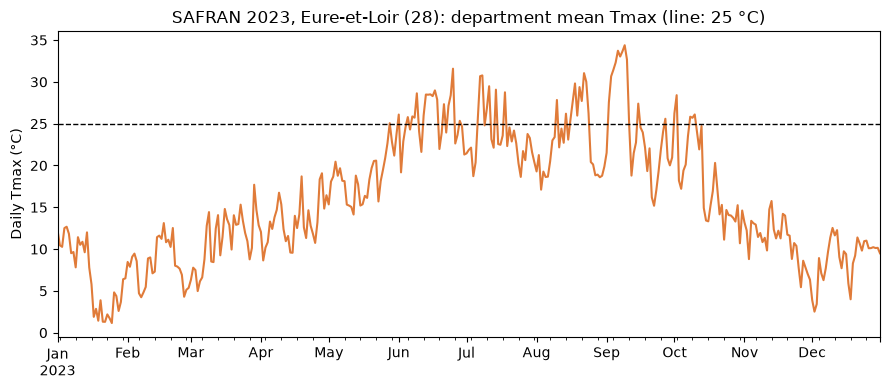

In [29]:
sim_dep = sim.merge(grid[["LAMBX", "LAMBY", "num_dep"]], on=["LAMBX", "LAMBY"], how="left")
eure = sim_dep[sim_dep["num_dep"] == 28].groupby("date")[["TSUP_H", "PRELIQ"]].mean()
print(sim_dep.loc[sim_dep["num_dep"] == 28, ["LAMBX", "LAMBY"]].drop_duplicates().shape[0], "cells in department 28")
ax = eure["TSUP_H"].plot(color="#E07B39")
ax.axhline(25, color="k", ls="--", lw=1)
ax.set_ylabel("Daily Tmax (°C)")
ax.set_xlabel("")
ax.set_title("SAFRAN 2023, Eure-et-Loir (28): department mean Tmax (line: 25 °C)")
plt.tight_layout()

## 3. Agreste SAA long series (annual agricultural statistics)

**What it is:** the official statistics of the Ministry of Agriculture: area, yield and production by crop, **department × year**, 2010-2025 (2025 provisional). Licence Ouverte. It is the **on-farm** reference (trial yields are well above farm yields).

The ZIP contains two Excel files (departmental and regional). We use the departmental one, sheet `COP` (cereals, oilseeds, protein crops), with the header on row 6 (`header=5`).

In [30]:
SAA_URL = ("https://agreste.agriculture.gouv.fr/agreste-web/download/publication/publie/"
           "SAA-SeriesLongues/SAA-SeriesLongues-2010-2025_DonneesProvisoires-DepartementalesRegionales.zip")
saa_zip = fetch(SAA_URL, DATA_DIR / "saa" / "SAA-SeriesLongues-2010-2025.zip")
with zipfile.ZipFile(saa_zip) as z:
    print(z.namelist())
    saa = pd.read_excel(z.open("SAA_2010-2025_provisoires_donnees_departementales.xlsx"),
                        sheet_name="COP", header=5)
print(saa.shape)
saa.iloc[:3, :8]

['SAA_2010-2025_provisoires_donnees_departementales.xlsx', 'SAA_2010-2025_provisoires_donnees_regionales.xlsx']


(4500, 52)


,LIB_REG2,LIB_DEP,LIB_SAA,STATUT_QUALITE,SURF_2010,SURF_2011,SURF_2012,SURF_2013
0,11 - Île-de-France,077 - Seine-et-Marne,01 - Blé tendre d'hiver et épeautre,1,135199.0,142512.0,137830.0,140610.0
1,11 - Île-de-France,077 - Seine-et-Marne,02 - Blé tendre de printemps,1,319.0,360.0,410.0,600.0
2,11 - Île-de-France,077 - Seine-et-Marne,03 - Total blé tendre (01 + 02),1,135518.0,142872.0,138240.0,141210.0


| Column | What it is |
|---|---|
| `LIB_REG2`, `LIB_DEP` | Region and department, as `"017 - Charente-Maritime"` (3-character code + name) |
| `LIB_SAA` | Crop, as `"41 - Pois protéagineux"` (protein pea, the one we care about) |
| `STATUT_QUALITE` | Data quality: 1 reliable, 2 and 3 less so, NC not computed |
| `SURF_AAAA` | Area (ha) |
| `REND_AAAA` | Yield (q/ha) |
| `PROD_AAAA` | Production (quintals; /10 = tonnes) |

It is wide format by year: we turn it into long format (`dep`, `year`, `surf`, `rend`, `prod`) so that it is easy to join.

In [31]:
pois = saa[saa["LIB_SAA"].astype(str).str.startswith("41 - Pois")].copy()
pois["dep"] = pois["LIB_DEP"].str.split(" - ").str[0].str[-2:]
pois = pois[pois["LIB_DEP"].str[0] == "0"]  # metropolitan departments only (codes 001..095, 02A, 02B)
long = pois.melt(id_vars=["dep", "LIB_DEP", "STATUT_QUALITE"],
                 value_vars=[c for c in pois.columns if c[:5] in ("SURF_", "REND_", "PROD_")])
long["value"] = pd.to_numeric(long["value"], errors="coerce")
long["var"] = long["variable"].str[:4].str.lower()
long["year"] = long["variable"].str[5:].astype(int)
saa_long = long.pivot_table(index=["dep", "LIB_DEP", "year"], columns="var", values="value").reset_index()
print(pois.shape[0], "departments;", saa_long.shape)
saa_long.head()

95 departments; (1520, 6)


var,dep,LIB_DEP,year,prod,rend,surf
0,01,001 - Ain,2010,2852.0,40.17,71.0
1,01,001 - Ain,2011,1659.0,31.90,52.0
2,01,001 - Ain,2012,1182.0,38.13,31.0
3,01,001 - Ain,2013,648.0,24.92,26.0
4,01,001 - Ain,2014,1278.0,29.05,44.0


**National series:** we sum area and production over all departments; the national yield is production / area. In the table, `surf` is in ha, `prod` in thousand tonnes, `rend` in q/ha.

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
var,,,,,,,,,,,,,,,,
surf,209980.0,162203.0,120421.0,109371.0,126657.0,155491.0,188022.0,186172.0,145362.0,153779.0,202692.0,194326.0,133485.0,151603.0,123071.0,97884.0
prod,902.0,564.2,472.6,425.4,455.5,557.4,439.1,629.4,494.9,594.9,558.8,552.2,399.9,485.2,348.4,348.1
rend,43.0,34.8,39.2,38.9,36.0,35.8,23.4,33.8,34.0,38.7,27.6,28.4,30.0,32.0,28.3,35.6


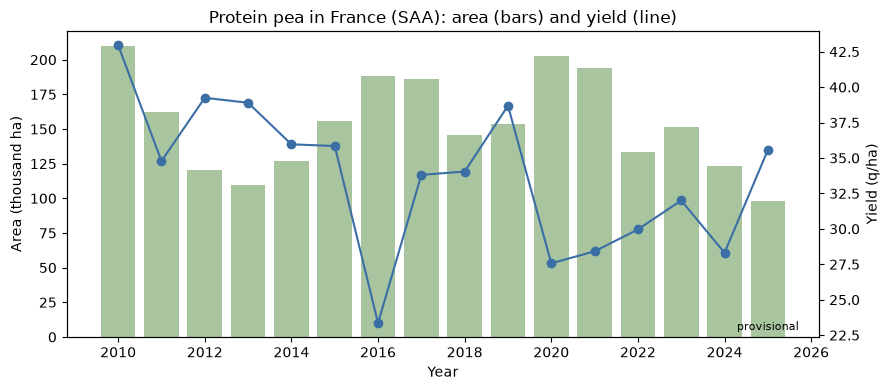

In [32]:
nat = saa_long.groupby("year")[["surf", "prod"]].sum()
nat["rend"] = nat["prod"] / nat["surf"]
nat["prod"] = nat["prod"] / 1e4  # quintals -> thousand tonnes
fig, ax = plt.subplots()
ax.bar(nat.index, nat["surf"] / 1000, color="#A9C5A0", label="area")
ax.set_ylabel("Area (thousand ha)")
ax.set_xlabel("Year")
ax2 = ax.twinx()
ax2.plot(nat.index, nat["rend"], color="#3A6EA5", marker="o", label="yield")
ax2.set_ylabel("Yield (q/ha)")
ax.set_title("Protein pea in France (SAA): area (bars) and yield (line)")
ax.text(2025, 5, "provisional", ha="center", fontsize=8)
plt.tight_layout()
nat.round(1).T

**SAA gotchas:**

- **Oise (60):** the yield is 9-16 q/ha in 2010-2019 and 30-43 since 2020. It is an artefact of the series (an error or a unit change), not agronomic: exclude Oise before 2020.
- **2025 is provisional** (the file name says so).
- The series is revised and back-cast: it is not what was known in real time.

In [33]:
saa_long[saa_long["dep"] == "60"].set_index("year")[["surf", "rend"]].T.round(1)

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
var,,,,,,,,,,,,,,,,
surf,12711.0,10477.0,8047.0,6896.0,7470.0,8023.0,9700.0,8640.0,7910.0,7335.0,10240.0,9850.0,6549.0,7870.0,7429.0,5258.0
rend,15.0,16.3,16.1,15.5,13.4,13.1,13.1,9.2,10.1,9.1,34.0,30.0,41.0,40.0,30.0,43.0


## 4. RPG (Registre Parcellaire Graphique): where it is grown

**What it is:** the parcels declared to the CAP (EU Common Agricultural Policy), with their crop, published by the IGN (vector data, one geometry per parcel). For pea there are two crop codes:

| Code | Crop |
|---|---|
| `PPR` | Pois de printemps (**spring** pea) |
| `PHI` | Pois d'hiver (**winter** pea) |

Downloading all the parcels is heavy, so here we use **two tables already aggregated** by department × year. **They were made before the event**: they must be declared as prior resources or regenerated during the hackathon.

- `research/datasets/rpg_pulses_dept_year.csv`: area by department × year × legume group (`pois_prot` = PPR + PHI), 2015-2024.
- `research/eda_idea1/context/rpg_winter_share_dept.csv`: pea area (PPR + PHI), PHI area and winter fraction (`share` = PHI / total) by department, **only for 2015, 2020 and 2024**.

In [34]:
RESEARCH = Path("../research")
rpg = pd.read_csv(RESEARCH / "datasets" / "rpg_pulses_dept_year.csv", dtype={"code_dep": str})
rpg_inv = pd.read_csv(RESEARCH / "eda_idea1" / "context" / "rpg_winter_share_dept.csv", dtype={"dep": str})
print(rpg.shape, rpg_inv.shape)
display(rpg["grp"].value_counts().to_frame("rows"))
rpg_inv.head()

(8336, 6) (264, 5)


,rows
grp,
feverole,880
melange_prot_cereales,879
pois_prot,873
lentille,860
pois_chiche,728
haricot_flageolet,668
lupin,648
autre,609
petits_pois,598


,year,dep,surface_ha,phi,share
0,2015,01,67.29,22.25,0.330658
1,2015,02,3722.86,421.15,0.113125
2,2015,03,603.35,308.71,0.511660
3,2015,04,731.87,508.14,0.694304
4,2015,05,30.09,1.54,0.051180


National pea area according to the RPG against the SAA (they agree within ±5%), and the national winter fraction for the 3 years where we have it.

In [35]:
r = rpg[rpg["grp"] == "pois_prot"].groupby("year")["surface_ha"].sum().to_frame("RPG ha")
r["SAA ha"] = nat["surf"]
inv = rpg_inv.groupby("year")[["surface_ha", "phi"]].sum()
r["fracción invierno"] = inv["phi"] / inv["surface_ha"]
r.round({"RPG ha": 0, "SAA ha": 0, "fracción invierno": 2})

,RPG ha,SAA ha,fracción invierno
year,,,
2015,157917.0,155491.0,0.19
2016,190891.0,188022.0,NaN
2017,190391.0,186172.0,NaN
2018,144964.0,145362.0,NaN
2019,148571.0,153779.0,NaN
2020,201056.0,202692.0,0.21
2021,195204.0,194326.0,NaN
2022,132917.0,133485.0,NaN
2023,149984.0,151603.0,NaN


**Optional: live query to the IGN WFS.** With `RESULTTYPE=hits` the server returns only the number of parcels, without geometries. It can be slow or fail, so it has a short timeout and a `try/except`: **do not use it live in the demo**.

In [36]:
params = {
    "SERVICE": "WFS", "VERSION": "2.0.0", "REQUEST": "GetFeature",
    "TYPENAMES": "RPG.2023:parcelles_graphiques",
    "RESULTTYPE": "hits", "CQL_FILTER": "code_cultu='PPR'",
}
try:
    resp = requests.get("https://data.geopf.fr/wfs/ows", params=params, timeout=30)
    import re
    m = re.search(r'numberMatched="(\d+)"', resp.text)
    print("PPR parcels in 2023:", m.group(1) if m else resp.text[:300])
except Exception as e:
    print("WFS did not respond in time, continuing without it:", type(e).__name__)

PPR parcels in 2023: 19211


## 5. Terres Univia quality surveys (protein in the silos)

**What it is:** every year Terres Inovia / Terres Univia samples pea lots on arrival at the silos and measures protein (N × 6.25, in % of dry matter, by NIRS). They publish a PDF ("qualité des graines de pois") with the national mean and the mean by basin. These are small tables: **they are not a training set**, they serve to calibrate the level and for context.

Two pieces:
1. The **national series** 2015-2025 (11 values), which we typed in by hand from the PDFs.
2. The **basin means** 2019-2025, already extracted to CSV before the event (`research/eda_idea1/context/terres_inovia_protein_basin_2019_2025.csv`, a prior resource to declare).

In [37]:
nat_prot = pd.Series(
    [22.9, 23.1, 22.4, 21.7, 22.2, 21.6, 22.7, 21.9, 24.4, 24.1, 22.8],
    index=range(2015, 2026), name="national protein (% DM)")
basin = pd.read_csv(RESEARCH / "eda_idea1" / "context" / "terres_inovia_protein_basin_2019_2025.csv")
print("Source: Terres Univia quality surveys, % DM")
basin.pivot(index="basin", columns="year", values="prot")

Source: Terres Univia quality surveys, % DM


year,2019,2020,2021,2022,2023,2024,2025
bassin,,,,,,,
Centre-IDF,22.1,21.4,22.8,21.7,25.0,24.5,23.3
Est,21.6,20.8,22.6,20.8,24.2,23.5,21.6
Grand Sud,22.6,21.9,24.4,23.1,24.1,24.0,23.7
Normandie/Nord,23.0,22.1,22.7,22.7,23.9,23.9,22.7
Ouest/Poitou-Ch.,22.2,22.0,22.5,23.1,24.5,23.9,23.5


We compare the national series with the annual mean of the Pea_dataset trials (all situations with protein). If the two lines move together, the trial protein is on the same scale as the silos (yield, on the other hand, is not: see section 6).

,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
national protein (% DM),22.9,23.1,22.4,21.7,22.2,21.6,22.7,21.9,24.4,24.1,22.8
Pea_dataset,22.9,23.8,22.5,20.8,22.0,22.7,23.4,22.4,24.8,24.0,NaN


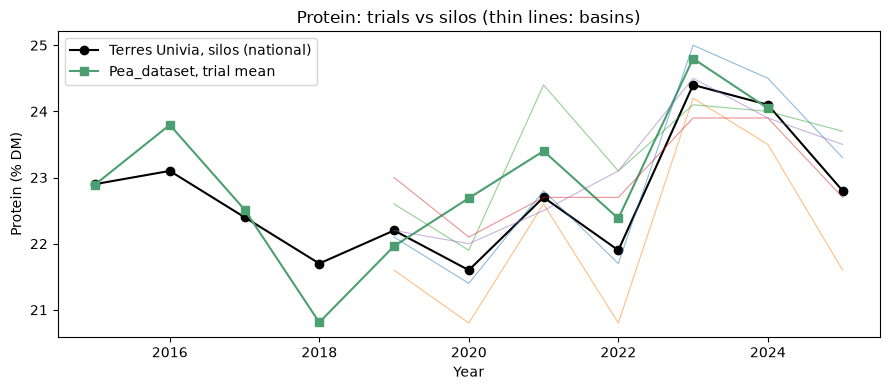

In [38]:
pea_year = prot.groupby("harvest_year")["protein_content"].mean().loc[2015:]
fig, ax = plt.subplots()
ax.plot(nat_prot.index, nat_prot, marker="o", color="k", label="Terres Univia, silos (national)")
ax.plot(pea_year.index, pea_year, marker="s", color="#4C9F70", label="Pea_dataset, trial mean")
for b, g in basin.groupby("basin"):
    ax.plot(g["year"], g["prot"], lw=0.8, alpha=0.5)
ax.set_xlabel("Year")
ax.set_ylabel("Protein (% DM)")
ax.set_title("Protein: trials vs silos (thin lines: basins)")
ax.legend()
plt.tight_layout()
pd.concat([nat_prot, pea_year.rename("Pea_dataset")], axis=1).round(1).T

## 6. How the data joins

| From | To | Key |
|---|---|---|
| `trials_data` | `crop_traits_data` | `situation_id` (100% match) |
| `trials_data` | weather in the zip | `weather_file` (file name, mixed case) |
| site | SAFRAN cell | lat/lon → nearest cell (`LAMBX`, `LAMBY`) |
| SAFRAN cell | department | `num_dep` from the DBF |
| site | department | first 2 digits of `postal_code` (except the 5 sites with bad coordinates) |
| department | SAA / RPG | 2-character department code |

**End-to-end example:** we take a spring trial from 2023 (the SAFRAN year we downloaded) in Eure-et-Loir (28), the department with the most situations.

In [39]:
cands = trial_agg[(trial_agg["harvest_year"] == 2023) & (trial_agg["pea_type"] == "SPRING") & (trial_agg["dep"] == "28")]
ex = cands.sort_values("n_var", ascending=False).iloc[0]
print(f"Trial: {ex['site_name']} | 2023 | SPRING | dep {ex['dep']} | {ex['n_var']} varieties")
rows = df[(df["site_name"] == ex["site_name"]) & (df["harvest_year"] == 2023) & (df["pea_type"] == "SPRING")]
rows[["situation_id", "genotype", "seed_prot", "sowing_date", "start_flo_date",
      "protein_content", "yield_14", "weather_file"]].head(8)

Trial: ERMENONVILLE_LA_PETITE | 2023 | SPRING | dep 28 | 23 varieties


,situation_id,genotype,seed_prot,sowing_date,start_flo_date,protein_content,yield_14,weather_file
2634,ERMENONVILLE_LA_PETITE__Genotype_58__2023,Genotype_58,high,2023-02-15,2023-05-26,25.8,54.8,ermenonville_la_petite_weather.csv
2635,ERMENONVILLE_LA_PETITE__Genotype_87__2023,Genotype_87,medium,2023-02-15,2023-05-26,25.1,54.1,ermenonville_la_petite_weather.csv
2636,ERMENONVILLE_LA_PETITE__Genotype_61__2023,Genotype_61,medium,2023-02-15,2023-05-22,25.1,52.4,ermenonville_la_petite_weather.csv
2637,ERMENONVILLE_LA_PETITE__Genotype_15__2023,Genotype_15,very high,2023-02-15,2023-05-26,27.0,50.2,ermenonville_la_petite_weather.csv
2638,ERMENONVILLE_LA_PETITE__Genotype_19__2023,Genotype_19,very high,2023-02-15,2023-05-25,24.8,47.1,ermenonville_la_petite_weather.csv
2639,ERMENONVILLE_LA_PETITE__Genotype_76__2023,Genotype_76,medium,2023-02-15,2023-05-26,25.6,54.5,ermenonville_la_petite_weather.csv
2640,ERMENONVILLE_LA_PETITE__Genotype_46__2023,Genotype_46,very high,2023-02-15,2023-05-26,26.5,57.2,ermenonville_la_petite_weather.csv
2641,ERMENONVILLE_LA_PETITE__Genotype_103__2023,Genotype_103,high,2023-02-15,2023-05-27,26.4,52.0,ermenonville_la_petite_weather.csv


Its weather from the zip (by `weather_file`) and its SAFRAN cell (by lat/lon), over the same window: from sowing to 31 July.

Site at (48.291, 1.13) -> SAFRAN cell LAMBX=5080, LAMBY=23690 at 3.5 km; sowing 2023-02-15


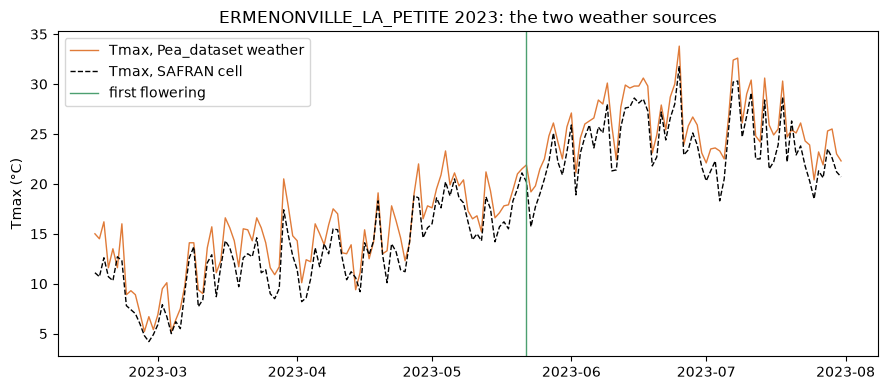

In [40]:
site = sites[sites["site_name"] == ex["site_name"]].iloc[0]
sow = pd.to_datetime(rows["sowing_date"].min())
print(f"Site at ({site['latitude']}, {site['longitude']}) -> SAFRAN cell "
      f"LAMBX={site['LAMBX']}, LAMBY={site['LAMBY']} at {site['dist_km']:.1f} km; sowing {sow.date()}")

wz_site = read_weather(rows["weather_file"].iloc[0]).set_index("date")
cell = sim[(sim["LAMBX"] == site["LAMBX"]) & (sim["LAMBY"] == site["LAMBY"])].set_index("date")
window = slice(sow, pd.Timestamp("2023-07-31"))

fig, ax = plt.subplots()
ax.plot(wz_site.loc[window, "TX"], color="#E07B39", lw=1, label="Tmax, Pea_dataset weather")
ax.plot(cell.loc[window, "TSUP_H"], color="k", lw=1, ls="--", label="Tmax, SAFRAN cell")
ax.axvline(rows["start_flo_date"].min(), color="#4C9F70", lw=1, label="first flowering")
ax.set_ylabel("Tmax (°C)")
ax.set_title(f"{ex['site_name']} 2023: the two weather sources")
ax.legend()
plt.tight_layout()

And the on-farm context of its department that year: SAA yield and RPG area, against what the trial gave.

In [41]:
d = ex["dep"]
saa_row = saa_long[(saa_long["dep"] == d) & (saa_long["year"] == 2023)].iloc[0]
rpg_ha = rpg[(rpg["grp"] == "pois_prot") & (rpg["code_dep"] == d) & (rpg["year"] == 2023)]["surface_ha"].sum()
share24 = rpg_inv[(rpg_inv["dep"] == d) & (rpg_inv["year"] == 2024)]["share"]
pd.Series({
    "trial mean protein (% DM)": ex["prot_mean"],
    "trial mean yield (q/ha)": ex["yield_mean"],
    f"SAA yield {saa_row['LIB_DEP']} 2023 (q/ha)": saa_row["rend"],
    "SAA area (ha)": saa_row["surf"],
    "RPG area 2023 (ha)": rpg_ha,
    "RPG winter fraction (2024, nearest year)": share24.iloc[0] if len(share24) else np.nan,
    "national silo protein 2023 (% DM)": nat_prot[2023],
}).round(2).to_frame("valor")

,valor
trial mean protein (% DM),26.00
trial mean yield (q/ha),51.03
SAA yield 028 - Eure-et-Loir 2023 (q/ha),38.00
SAA area (ha),7681.00
RPG area 2023 (ha),7455.74
"RPG winter fraction (2024, nearest year)",0.19
national silo protein 2023 (% DM),24.40


## 7. Summary

| Dataset | Type | Granularity | Range | Role in idea 1 |
|---|---|---|---|---|
| Pea_dataset `trials_data` (INRAE, doi 10.57745/FW78RE) | Tabular | Situation = site × variety × year (4,450) | 2002-2024 (useful 2013-2024) | Inputs: location, soil, type, variety class, sowing |
| Pea_dataset `crop_traits_data` | Tabular, long format | Situation × variable | same | **Labels**: protein (% DM), yield (q/ha at 14%), flowering |
| Pea_dataset `weather_data.zip` | Daily time series | Site (158 files) | Only the season of each trial | Check; no use for climatology |
| SAFRAN / SIM2 (Météo-France) | Daily time series on a grid | 8 km cell (9,892) → site or department | 1958 to yesterday | Climate by phase, scenarios, live season |
| Agreste SAA long series | Annual panel | Department × year | 2010-2025 (2025 provisional) | On-farm yield and area |
| RPG (IGN), aggregated | Vector → table | Department × year × code (PPR/PHI) | 2015-2024 | Weight of each department, winter fraction |
| Terres Univia surveys | Small table (from PDFs) | National (11 values) and 5 basins | 2015-2025 / 2019-2025 | Calibrate protein level against the silos |

**Key takeaway:** the real unit is the **trial** (site × year × type, ~250 with protein); trial protein is on the silo scale, yield is not (use relative yield); and climate for training and operating should always come from SAFRAN.

In [42]:
print(f"Full notebook in {time.time() - T0:.0f} s")

Full notebook in 5 s
